In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris

data = load_iris()

X = data.data
y = data.target

#Test on 20% of the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # For reproducibility

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# The prediction
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print(f"Model Accuracy: {accuracy * 100:.2f}")  # To to s.f

Model Accuracy: 100.00


In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Prepare the Data (Download the MNIST handwritten digits dataset)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# 2. Define the Neural Network Architecture
class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()
        # Input layer: 28x28 pixels = 784. Hidden layer: 128 neurons.
        self.fc1 = nn.Linear(28 * 28, 128)
        # Hidden layer to output layer: 10 classes (digits 0-9)
        self.fc2 = nn.Linear(128, 10)      

    def forward(self, x):
        x = x.view(-1, 28 * 28)            # Flatten the 2D image into a 1D array
        x = torch.relu(self.fc1(x))        # Pass through hidden layer with ReLU activation
        x = self.fc2(x)                    # Pass to output layer
        return x

# 3. Initialize the Model, Loss Function, and Optimizer
model = SimpleNet()
criterion = nn.CrossEntropyLoss() # Measures how wrong the model is
optimizer = optim.Adam(model.parameters(), lr=0.001) # The algorithm that updates the weights

# 4. Train the Model
print("Starting training...")
epochs = 3
for epoch in range(epochs):
    for batch_idx, (images, labels) in enumerate(train_loader):
        optimizer.zero_grad()              # Clear previous gradients
        outputs = model(images)            # Forward pass: make a prediction
        loss = criterion(outputs, labels)  # Calculate the error (Loss)
        loss.backward()                    # Backward pass: calculate how to adjust weights
        optimizer.step()                   # Update the weights
        
    print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.4f}")

print("Training complete!")

Starting training...
Epoch 1/3 | Loss: 0.2448
Epoch 2/3 | Loss: 0.1200
Epoch 3/3 | Loss: 0.0276
Training complete!


In [13]:
# Load the test dataset (10,000 images)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# Test the model
correct = 0
total = 0
with torch.no_grad(): # We don't need to calculate gradients when testing
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1) # Get the highest probability
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy on 10,000 unseen images: {100 * correct / total:.2f}%")

Test Accuracy on 10,000 unseen images: 97.36%


In [16]:
X = torch.tensor([[2.0]])
y = torch.tensor([[4.0]])

class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)  #One neuron input, one neuron output

    def forward(self, x):
        return self.linear(x)

model = SimpleNet()

criterion = nn.MSELoss() #Mean Square Error Loss
optimizer = optim.SGD(model.parameters(), lr=0.1) # Stochastic Gradient Descent


print(f"Initial Guess: {model(X).item():.4f}")

for i in range(10):
    optimizer.zero_grad() # Clears old math, computations and gradients
    output = model(X)
    loss = criterion(output, y)
    loss.backward()
    optimizer.step()

print(f"Final guess for 2.0: {model(X).item():.4f}")


        

Initial Guess: 0.0248
Final guess for 2.0: 4.0000


Training CNN... (this might take a minute on a CPU)
Epoch 1/2 complete.
Epoch 2/2 complete.
Model saved to 'lyra_mnist_brain.pth'!


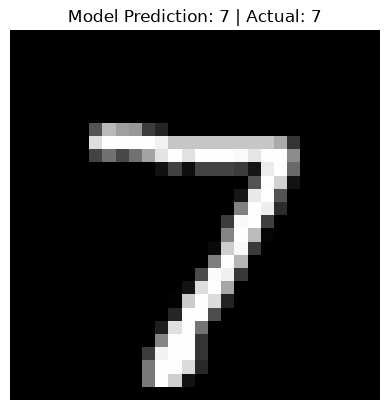

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. PREPARE DATA
# ==========================================
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# ==========================================
# 2. THE CNN ARCHITECTURE (UPGRADE 3)
# ==========================================
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Conv2d looks at 2D patches (1 input channel for grayscale, 32 output channels)
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2) # Shrinks the image by half
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        
        # After two pools, a 28x28 image becomes 7x7. 64 channels * 7 * 7 = 3136
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)  # Output 10 neurons 0 - 9

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7) # Flatten
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 3. TRAIN
# ==========================================
print("Training CNN... (this might take a minute on a CPU)")
epochs = 2 # CNNs are heavy, 2 epochs is enough to get >98%
for epoch in range(epochs):
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
    print(f"Epoch {epoch+1}/{epochs} complete.")

# ==========================================
# 4. SAVE THE BRAIN (UPGRADE 2)
# ==========================================
torch.save(model.state_dict(), 'lyra_mnist_brain.pth')
print("Model saved to 'lyra_mnist_brain.pth'!")

# ==========================================
# 5. VISUALIZE THE PREDICTION (UPGRADE 1)
# ==========================================
# Grab a random image from the test set
dataiter = iter(test_loader)
images, labels = next(dataiter)

# Get a prediction
with torch.no_grad():
    output = model(images[0].unsqueeze(0)) # Add batch dimension
    _, predicted = torch.max(output, 1)

# Show the image and the result
plt.imshow(images[0].squeeze(), cmap='gray')
plt.title(f"Model Prediction: {predicted.item()} | Actual: {labels[0].item()}")
plt.axis('off')
plt.show()